# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [1]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [2]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [3]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.60MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.03MB/s]


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [11]:
 #Conv is a convolutional layer that doesn't change the image resolution, only the channel dimension
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        #Conv2d(kernel_size, stride, padding) is nn.Conv2d()
        #nn.Conv2d(3,1,1) based on the image
        #BN is nn.BatchNorm2d()
        #GELU is nn.GELU()

        self.net = nn.Sequential(nn.Conv2d(in_channels, out_channels, 3, 1, 1),
                                 nn.BatchNorm2d(out_channels),
                                 nn.GELU())

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====


#DownConv is a convolutional layer that downsamples the tensor by 2.
class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(nn.Conv2d(in_channels, out_channels, 3, 2, 1),
                                 nn.BatchNorm2d(out_channels),
                                 nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====


#UpConv is a convolutional layer that upsamples the tensor by 2.
class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1),
                                 nn.BatchNorm2d(out_channels),
                                 nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====



#Flatten is an average pooling layer that flattens a 7x7 tensor into a 1x1 tensor. 7 is the resulting height and width after the downsampling operations.
class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        #7+gelu
        self.net = nn.Sequential(nn.AvgPool2d(7), nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====


#Unflatten is a convolutional layer that unflattens/upsamples a 1x1 tensor into a 7x7 tensor.
class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        #77n+bn+gelu
        self.net = nn.Sequential(nn.ConvTranspose2d(in_channels, in_channels, 7, 7, 0),
                                nn.BatchNorm2d(in_channels),
                                nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====


#conv -> conv
class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(Conv(in_channels, out_channels), Conv(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====


#downconv -> convbloack
class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(DownConv(in_channels, out_channels), ConvBlock(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====

#Upcov -> Convblock
class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(UpConv(in_channels, out_channels), ConvBlock(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====

In [ ]:
#test
#why upconv fail? <- parameter

x = torch.randn(2, 3, 32, 32).to(device)

x = Conv(3, 64).to(device)(x)
print("Conv", x.shape)

x = DownConv(64, 128).to(device)(x)
print("DownC:", x.shape)

x = UpConv(128, 32).to(device)(x)
print("UpC:", x.shape)


Conv torch.Size([2, 64, 32, 32])
DownC: torch.Size([2, 128, 16, 16])
UpC: torch.Size([2, 32, 32, 32])


## Implementing Unconditional UNet

In [ ]:
#Concat is a channel-wise concatenation between tensors with the same 2D shape. This is simply torch.cat().

#process: input ->convblock1 ->Downblock1 ->Downblock2 ->
#upblock1-> upblock2 ->convbloack
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====

        #Encoder
        #(C 28 28)
        self.convBlock_in = ConvBlock(in_channels, num_hiddens)
        #(D 28 28)
        self.downBlock1 = DownBlock(num_hiddens, num_hiddens)
        #(D 14 14)
        self.downBlock2 = DownBlock(num_hiddens, 2 * num_hiddens)
        #(2D 7 7)

        #Bottleneck
        self.flatten = Flatten()
        #(2D 1 1)
        self.unflatten = Unflatten(2 * num_hiddens)
        #(2D 7 7)

        #Decoder
        #concat (2D 7 7) + (2D 7 7) = (4D 7 7)
        self.upBlock1 = UpBlock(4 * num_hiddens, num_hiddens)
        #(D 14 14)

        #concat (D 14 14) + (D 14 14) = (2D 14 14)
        self.upBlock2 = UpBlock(2 * num_hiddens, num_hiddens)
        #(D 28 28)

        #concat (D 28 28) + (D 28 28) = (2D 28 28)
        self.convBlock_out = ConvBlock(2 * num_hiddens, num_hiddens)
        #(D 28 28)
        self.output = nn.Conv2d(num_hiddens, in_channels, 3, 1, 1)
        #(C 28 28)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====

        # Encoder
        x1 = self.convBlock_in(x)  # (D 28 28)
        x2 = self.downBlock1(x1)   # (D 14 14)
        x3 = self.downBlock2(x2)   # (2D 7 7)

        # Bottleneck
        x4 = self.flatten(x3)      # (2D 1 1)
        x4 = self.unflatten(x4)    # (2D 7 7)

        # Decoder
        # (4D 7 7) -> (D 14 14)
        x = self.upBlock1(torch.cat([x4, x3], dim=1))

        # (2D 14 14) -> (D 28 28)
        x = self.upBlock2(torch.cat([x, x2], dim=1))            # (D 28 28)

        # (2D 28 28) -> (D 28 28)
        x = self.convBlock_out(torch.cat([x, x1], dim=1))       # (D 28 28)

        x = self.output(x)

        return x
        # ===== end of code ====


# Part 1.2: Using the UNet to Train a Denoiser

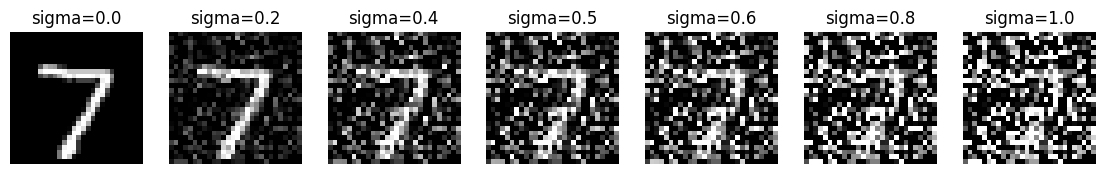

In [ ]:
# Visualize images at different noisy level

# z= x + sigma*noise
# ===== your code here! ====
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]

image, f = test_dataset[0]
noise = torch.randn_like(image)

plt.figure(figsize=(14, 3))
for i in range(len(sigmas)):
    sigma = sigmas[i]
    noisy_image = image + sigma * noise

    plt.subplot(1, 7, i + 1)
    plt.imshow(noisy_image.squeeze().clamp(0, 1), cmap="gray")
    plt.title(f"sigma={sigma}")
    plt.axis("off")

plt.show()

# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [ ]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

In [ ]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(1, hidden_dim).to(device)
#Use Adam optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

In [4]:
from tqdm.auto import tqdm

In [ ]:
# The training loops
train_losses = []
for epoch in range(num_epochs):
    for i, (images, _) in enumerate(tqdm(train_loader)):


        # ===== your code here! ====
        images = images.to(device)
        noisy_images = images + noise_level * torch.randn_like(images)
        outputs = model(noisy_images)

        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    #save for latter part comparison
    torch.save(model.state_dict(), OUT / f"training_epoch_{epoch+1}.pt")

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

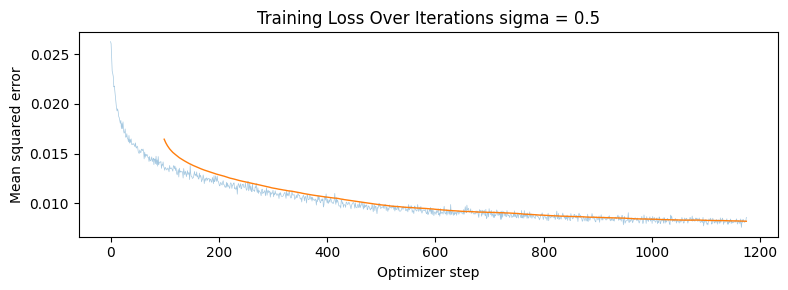

In [ ]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, "Training Loss Over Iterations sigma = 0.5")
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

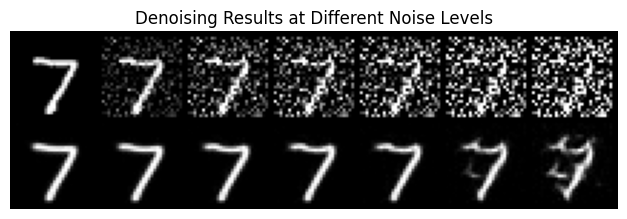

In [ ]:
# Visualize OOD testing
# ===== your code here! ====

#Visualize the denoiser results on test set digits with varying levels of noise
sigmas = [0., 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]

model.load_state_dict(torch.load(OUT / "training_epoch_5.pt", map_location=device))
model.eval()

image, label = test_dataset[0]
image = image.to(device)
#only sample one random noise for each noise level
noise = torch.randn_like(image)

noisy_images = []
for s in sigmas:
    noisy_images.append(image + s * noise)
noisy_images = torch.stack(noisy_images)

with torch.no_grad():
    outputs = model(noisy_images)

#visualize
all_images = torch.cat([noisy_images, outputs], dim=0)
show_grid(all_images, "Denoising Results at Different Noise Levels", "OOD122.png", nrow=7)


# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

In [ ]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4, batch size 256.

# Input is independent Gaussian noise, target is a clean digit.
pure_noise_model = UnconditionalUNet(1, hidden_dim).to(device)
pure_optimizer = torch.optim.Adam(pure_noise_model.parameters(), lr=learning_rate)
pure_losses = []



In [ ]:

for epoch in range(num_epochs):
    pure_noise_model.train()

    for i, (images, label) in enumerate(tqdm(train_loader)):

        images = images.to(device)

        #1.2.1 noisy_images = images + noise_level * torch.randn_like(images)
        #directly train on pure noise
        noise = torch.randn_like(images)
        outputs = pure_noise_model(noise)

        ####same as above
        loss = criterion(outputs, images)
        pure_optimizer.zero_grad()
        loss.backward()
        pure_optimizer.step()

        pure_losses.append(loss.item())

    torch.save(pure_noise_model.state_dict(), OUT / f"pure_noise_training_epoch_{epoch+1}.pt")

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

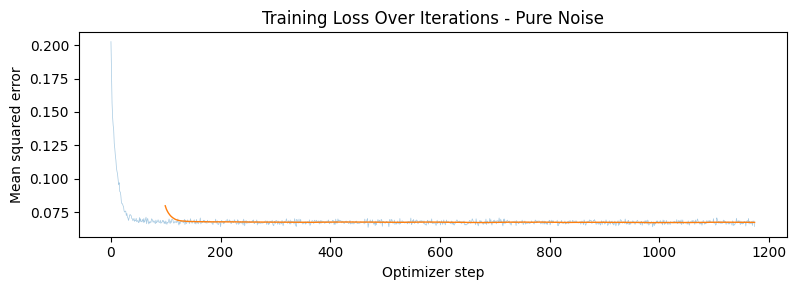

In [ ]:
# Plot losses
loss_plot(pure_losses, "Training Loss Over Iterations - Pure Noise")

#relationship between pure noise and ground truth... what does the model learn
#like a averge shape of the sample data
#mse loss calculation learn what


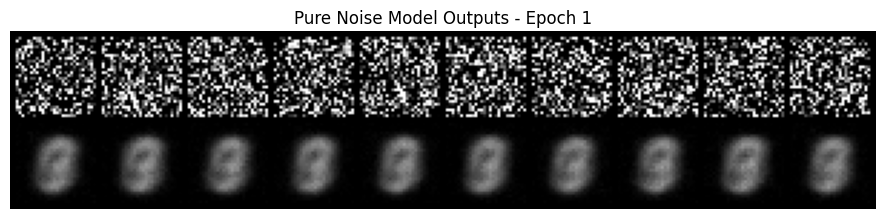

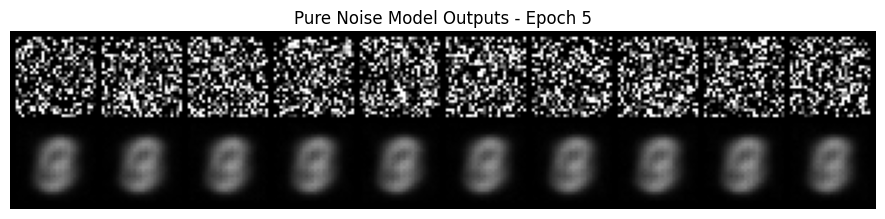

In [ ]:
#show held-out results at epochs 1 and 5, and explain averaging.
noise = torch.randn(10, 1, 28, 28).to(device)

for epoch in [1, 5]:
    pure_noise_model.load_state_dict(torch.load(OUT / f"pure_noise_training_epoch_{epoch}.pt", map_location=device))
    pure_noise_model.eval()

    #inference task. no need to re-train again
    with torch.no_grad():
        outputs = pure_noise_model(noise)

    show_grid(torch.cat([noise, outputs]), f"Pure Noise Model Outputs - Epoch {epoch}", f"pure_noise_epoch_{epoch}.png", nrow=10)

# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [5]:

#compared to unet. add two extra FCB for injecting time t
#one to unflatten
#one to first upblack

class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        #Fin->(linear(fin,fout)+gelu)fout->linear(fout,fout)->fout
        self.net = nn.Sequential(nn.Linear(in_channels, out_channels),
                            nn.GELU(),
                            nn.Linear(out_channels, out_channels))

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====



class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====

        #Encoder
        #(C 28 28)
        self.convBlock_in = ConvBlock(in_channels, num_hiddens)
        #(D 28 28)
        self.downBlock1 = DownBlock(num_hiddens, num_hiddens)
        #(D 14 14)
        self.downBlock2 = DownBlock(num_hiddens, 2 * num_hiddens)
        #(2D 7 7)

        #Bottleneck
        self.flatten = Flatten()
        #(2D 1 1)
        self.unflatten = Unflatten(2 * num_hiddens)
        #(2D 7 7)


        # Time conditioning
        self.fc1_t = FCBlock(1, 2 * num_hiddens)
        self.fc2_t = FCBlock(1, num_hiddens)

        #Decoder
        #concat (2D 7 7) + (2D 7 7) = (4D 7 7)
        self.upBlock1 = UpBlock(4 * num_hiddens, num_hiddens)
        #(D 14 14)

        #concat (D 14 14) + (D 14 14) = (2D 14 14)
        self.upBlock2 = UpBlock(2 * num_hiddens, num_hiddens)
        #(D 28 28)

        #concat (D 28 28) + (D 28 28) = (2D 28 28)
        self.convBlock_out = ConvBlock(2 * num_hiddens, num_hiddens) #(D 28 28)
        self.output = nn.Conv2d(num_hiddens, in_channels, 3, 1, 1)
        #(C 28 28)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        # Encoder
        x1 = self.convBlock_in(x)  #(D 28 28)
        x2 = self.downBlock1(x1)   #(D 14 14)
        x3 = self.downBlock2(x2)   #(2D 7 7)

        # Bottleneck
        x4 = self.flatten(x3)      #(2D 1 1)
        x4 = self.unflatten(x4)    #(2D 7 7)

        # Time Conditioning
        t = t.view(-1, 1)
        #project to higher hidden dimension
        t1 = self.fc1_t(t)[:, :, None, None]  #(2D 1 1)
        t2 = self.fc2_t(t)[:, :, None, None]  #(D 1 1)

        # Decoder
        # t1
        x4 = x4 * t1  #(2D 7 7)

        # t2
        # (4D 7 7) -> (D 14 14)
        x = self.upBlock1(torch.cat([x4, x3], dim=1)) * t2


        # (2D 14 14) -> (D 28 28)
        x = self.upBlock2(torch.cat([x, x2], dim=1))
        # (2D 28 28) -> (D 28 28)
        x = self.convBlock_out(torch.cat([x, x1], dim=1))
        x = self.output(x)  #(C 28 28)

        return x
        # ===== end of code ====


## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [6]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    #sample noise and time
    #x0 pure noise; x1 real image
    N = x_1.shape[0]
    #sample a noise from same gassian distribution of x_1
    x_0 = torch.randn_like(x_1)
    t = torch.rand(N, device=x_1.device)

    # Interpolate
    t_img = t.view(-1, 1, 1, 1)
    x_t = (1 - t_img) * x_0 + t_img * x_1

    pred = unet(x_t, t)
    ground_truth = x_1 - x_0
    loss = F.mse_loss(pred, ground_truth)
    return loss
    # ===== end of code ====


In [7]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    torch.manual_seed(seed)
    device = next(unet.parameters()).device

    #generate initial gussan noise
    x = torch.randn(1, 1, img_wh[0], img_wh[1], device=device)

    for i in range(num_ts):
        step_width = i / num_ts
        t = torch.tensor([step_width], device=device)
        velocity = unet(x, t)
        one_step_width = 1 / num_ts
        x = x + one_step_width * velocity

    return x
    # ===== end of code ====


In [8]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

In [9]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====

batch_size = 64
learning_rate = 1e-2
hidden_dim = 64
#5
num_epochs = 10

time_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# ===== end of code ====

In [12]:
# Define your model, optimizer, and loss

#nn that predict on velocity
time_unet = TimeConditionalUNet(1, 10, hidden_dim).to(device)
#model wrapper
time_model = TimeConditionalFM(time_unet, num_ts=50).to(device)

#Use Adam optimizer with an initial learning rate of 1e-2.
time_optimizer = torch.optim.Adam(time_model.parameters(), lr=learning_rate)
time_scheduler = torch.optim.lr_scheduler.ExponentialLR(time_optimizer, gamma=0.1 ** (1 / num_epochs))

In [ ]:
# The training loops
time_losses = []

for epoch in range(num_epochs):
    time_model.train()

    for images, _ in tqdm(time_loader):
        images = images.to(device)

        loss = time_model(images)

        #backpropogate and update
        time_optimizer.zero_grad()
        loss.backward()
        time_optimizer.step()

        time_losses.append(loss.item())

    #You should call scheduler.step() after every epoch.
    time_scheduler.step()
    torch.save(time_model.state_dict(), OUT / f"tfm_epoch_{epoch+1}.pt")

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

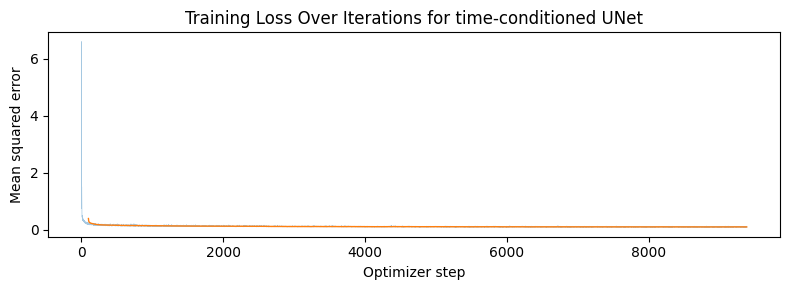

In [ ]:
# Visualize your training curve

loss_plot(time_losses, "Training Loss Over Iterations for time-conditioned UNet")


# Part 2.3: Sampling from the Time-conditioned UNet

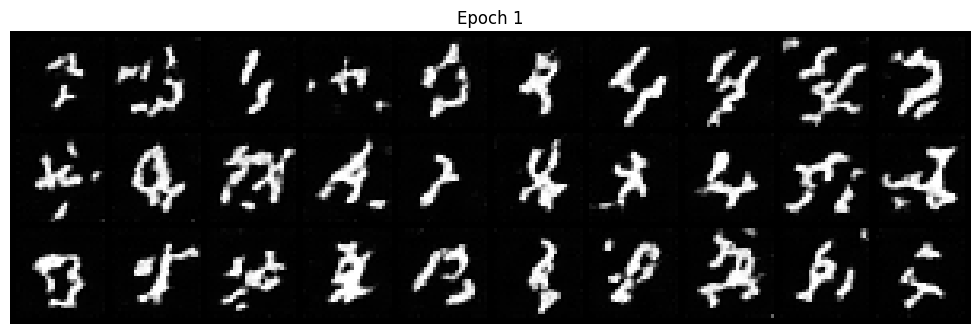

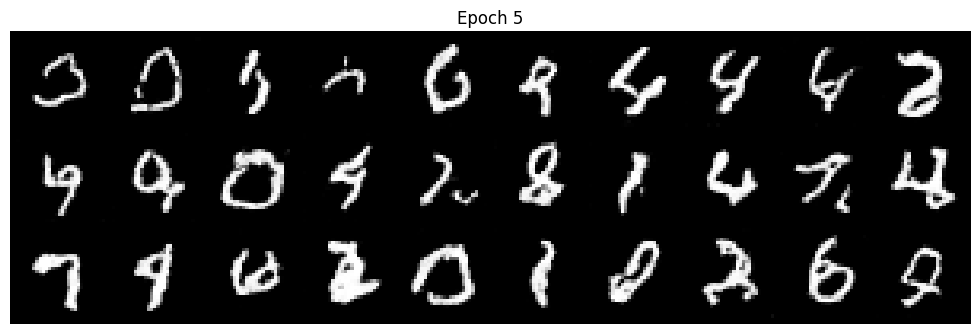

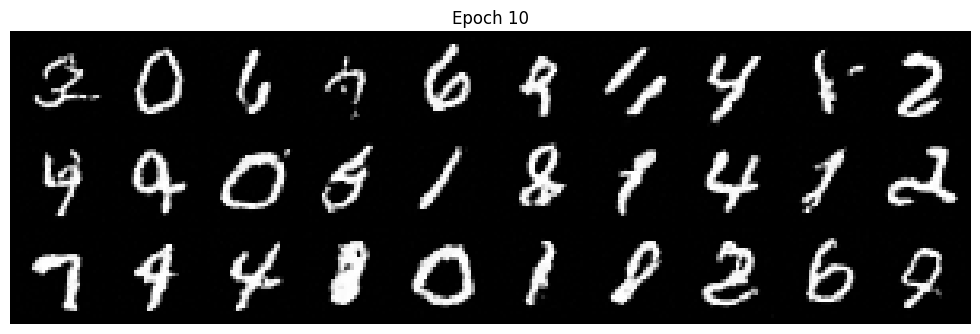

In [ ]:
# Sampling from the UNet
# ===== your code here! ====

for epoch in [1, 5, 10]:
    time_model.load_state_dict(
        torch.load(OUT / f"tfm_epoch_{epoch}.pt", map_location=device, weights_only=True))
    time_model.eval()

    generated_images = []
    for i in range(30):
        generated_images.append(time_model.sample((28, 28), seed=i))

    generated_images = torch.cat(generated_images, dim=0)
    show_grid(generated_images, f"Epoch {epoch}", f"tfm_epoch_{epoch}.png", nrow=10)

# ===== end of code ====

#CS280 bell and whiskles - how more ephochs perform

---



In [16]:
# Bells & Whistles: longer training

moreepoch_epochs = 20
moreepoch_hidden_dim = 64
moreepoch_lr = 1e-2

moreepoch_unet = TimeConditionalUNet(1, 10, moreepoch_hidden_dim).to(device)
moreepoch_model = TimeConditionalFM(moreepoch_unet, num_ts=50).to(device)

moreepoch_optimizer = torch.optim.Adam(
    moreepoch_model.parameters(), lr=moreepoch_lr
)

moreepoch_scheduler = torch.optim.lr_scheduler.ExponentialLR(
    moreepoch_optimizer, gamma=0.1 ** (1 / moreepoch_epochs)
)

In [17]:
# Training loops
moreepoch_losses = []

for epoch in range(moreepoch_epochs):
    moreepoch_model.train()

    for images, _ in tqdm(time_loader):
        images = images.to(device)

        loss = moreepoch_model(images)

        moreepoch_optimizer.zero_grad()
        loss.backward()
        moreepoch_optimizer.step()

        moreepoch_losses.append(loss.item())

    moreepoch_scheduler.step()
    torch.save(
        moreepoch_model.state_dict(),
        OUT / f"moreepoch_time_epoch_{epoch+1}.pt"
    )

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

...

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

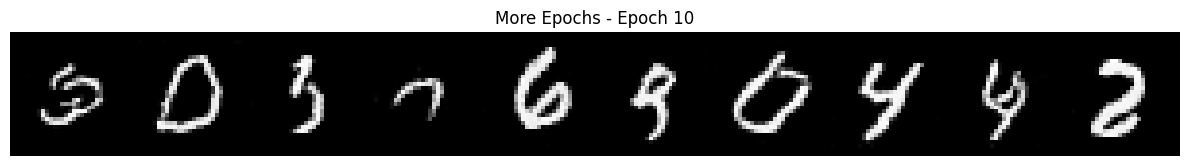

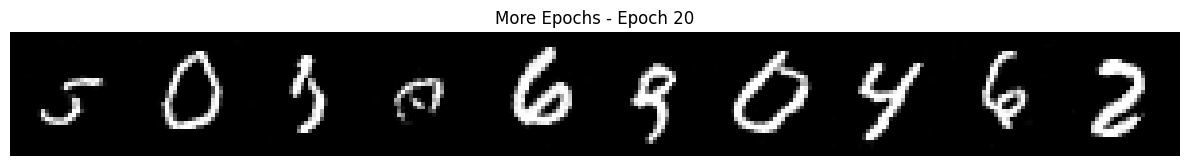

In [22]:
# Compare Epoch 11 and Epoch 21
for epoch in [10, 20]:
    moreepoch_model.load_state_dict(torch.load(
        OUT / f"moreepoch_time_epoch_{epoch}.pt",
        map_location=device, weights_only=True
    ))
    moreepoch_model.eval()

    samples = []
    for i in range(10):
        samples.append(moreepoch_model.sample((28, 28), seed=i))

    show_grid(torch.cat(samples, dim=0),
              f"More Epochs - Epoch {epoch}",
              f"moreepoch_time_epoch_{epoch}.png", nrow=10)

# Part 2.4: Implementing a Class-conditioned UNet

In [ ]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        self.num_classes = num_classes
        #Encoder
        #(C 28 28)
        self.convBlock_in = ConvBlock(in_channels, num_hiddens)
        #(D 28 28)
        self.downBlock1 = DownBlock(num_hiddens, num_hiddens)
        #(D 14 14)
        self.downBlock2 = DownBlock(num_hiddens, 2 * num_hiddens)
        #(2D 7 7)

        #Bottleneck
        self.flatten = Flatten()
        #(2D 1 1)
        self.unflatten = Unflatten(2 * num_hiddens)
        #(2D 7 7)


        # Time conditioning
        self.fc1_t = FCBlock(1, 2 * num_hiddens)
        self.fc2_t = FCBlock(1, num_hiddens)
        # Class conditioning
        self.fc1_c = FCBlock(num_classes, 2 * num_hiddens)
        self.fc2_c = FCBlock(num_classes, num_hiddens)

        #Decoder
        #concat (2D 7 7) + (2D 7 7) = (4D 7 7)
        self.upBlock1 = UpBlock(4 * num_hiddens, num_hiddens)
        #(D 14 14)

        #concat (D 14 14) + (D 14 14) = (2D 14 14)
        self.upBlock2 = UpBlock(2 * num_hiddens, num_hiddens)
        #(D 28 28)

        #concat (D 28 28) + (D 28 28) = (2D 28 28)
        self.convBlock_out = ConvBlock(2 * num_hiddens, num_hiddens) #(D 28 28)
        self.output = nn.Conv2d(num_hiddens, in_channels, 3, 1, 1)
        #(C 28 28)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        x1 = self.convBlock_in(x)  #(D 28 28)
        x2 = self.downBlock1(x1)   #(D 14 14)
        x3 = self.downBlock2(x2)   #(2D 7 7)

        # Bottleneck
        x4 = self.flatten(x3)      #(2D 1 1)
        x4 = self.unflatten(x4)    #(2D 7 7)

        # Time Conditioning and class conditioning
        t = t.view(-1, 1)

        #10% of the time, we drop the class conditioning vector c by setting it to 0.
        c = F.one_hot(c, num_classes=self.num_classes).float()
        if mask is not None:
            mask = mask.view(-1, 1)
            c = c * mask


        #project to higher hidden dimension -- embedding
        t1 = self.fc1_t(t)[:, :, None, None]  #(2D 1 1)
        t2 = self.fc2_t(t)[:, :, None, None]  #(D 1 1)
        c1 = self.fc1_c(c)[:, :, None, None]
        c2 = self.fc2_c(c)[:, :, None, None]

        # Decoder
        # t1
        x4 = c1 * x4 * t1  #(2D 7 7)

        # t2
        # (4D 7 7) -> (D 14 14)
        x = c2 * self.upBlock1(torch.cat([x4, x3], dim=1)) * t2


        # (2D 14 14) -> (D 28 28)
        x = self.upBlock2(torch.cat([x, x2], dim=1))
        # (2D 28 28) -> (D 28 28)
        x = self.convBlock_out(torch.cat([x, x1], dim=1))
        x = self.output(x)  #(C 28 28)

        return x
        # ===== end of code ====


In [ ]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    #sample noise and time
    #x0 pure noise; x1 real image
    N = x_1.shape[0]
    #sample a noise from same gassian distribution of x_1
    x_0 = torch.randn_like(x_1)
    t = torch.rand(N, device=x_1.device)

    #dropout
    mask = (torch.rand(N, device=x_1.device) > p_uncond).float()

    # Interpolate
    t_img = t.view(-1, 1, 1, 1)
    x_t = (1 - t_img) * x_0 + t_img * x_1

    pred = unet(x_t, c, t, mask)
    ground_truth = x_1 - x_0
    loss = F.mse_loss(pred, ground_truth)
    return loss
    # ===== end of code ====

In [ ]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    # ===== your code here! ====
    torch.manual_seed(seed)
    device = next(unet.parameters()).device

    c = c.to(device)
    N = c.shape[0]

    #generate initial gussan noise
    #this is different. should use N <-- unmatch the latter part
    x = torch.randn(N, 1, img_wh[0], img_wh[1], device=device)

    for i in range(num_ts):
        t = torch.full((N,), i / num_ts, device=device)

        cond_pred = unet(x, c, t, torch.ones(N, device=device))
        uncond_pred = unet(x, c, t, torch.zeros(N, device=device))

        #CFG
        guided_pred = uncond_pred + guidance_scale * (cond_pred - uncond_pred)
        x = x + (1 / num_ts) * guided_pred

    return x
    # ===== end of code ====


In [ ]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

In [ ]:
batch_size = 64
learning_rate = 1e-2
hidden_dim = 64
num_epochs = 10

In [ ]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).

class_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

class_unet = ClassConditionalUNet(1, 10, hidden_dim).to(device)
class_model = ClassConditionalFM(class_unet, num_ts=300, p_uncond=0.1).to(device)

class_optimizer = torch.optim.Adam(class_model.parameters(), lr=learning_rate)
class_scheduler = torch.optim.lr_scheduler.ExponentialLR(class_optimizer, gamma=0.1 ** (1 / num_epochs))

In [ ]:
# Save checkpoints at epochs 1,5,10.
class_losses = []

for epoch in range(num_epochs):
    class_model.train()

    for images, labels in tqdm(class_loader):
        images = images.to(device)
        labels = labels.to(device)

        loss = class_model(images, labels)

        #backpropogate and update
        class_optimizer.zero_grad()
        loss.backward()
        class_optimizer.step()

        class_losses.append(loss.item())

    class_scheduler.step()
    torch.save(class_model.state_dict(), OUT / f"class_tfm_epoch_{epoch+1}.pt")

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

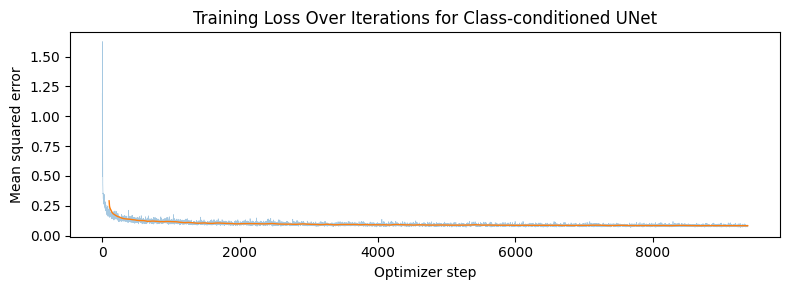

In [ ]:
#visualization
loss_plot(class_losses, "Training Loss Over Iterations for Class-conditioned UNet")

In [ ]:
# Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.
# No-Scheduler

class_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

no_scheduler_class_unet = ClassConditionalUNet(1, 10, hidden_dim).to(device)
no_scheduler_class_model = ClassConditionalFM(no_scheduler_class_unet, num_ts=300, p_uncond=0.1).to(device)

no_scheduler_class_optimizer = torch.optim.Adam(no_scheduler_class_model.parameters(), lr=learning_rate)

In [ ]:

no_scheduler_losses = []

for epoch in range(10):
    no_scheduler_class_model.train()

    for images, labels in tqdm(class_loader):
        images = images.to(device)
        labels = labels.to(device)

        loss = no_scheduler_class_model(images, labels)

        no_scheduler_class_optimizer.zero_grad()
        loss.backward()
        no_scheduler_class_optimizer.step()

        no_scheduler_losses.append(loss.item())


    torch.save(no_scheduler_class_model.state_dict(), OUT / f"ns_class_epoch_{epoch+1}.pt")


  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

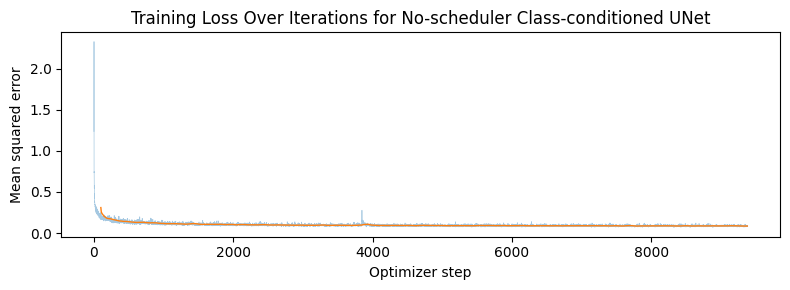

In [ ]:
#visualization
loss_plot(no_scheduler_losses, "Training Loss Over Iterations for No-scheduler Class-conditioned UNet")

# Part 2.6: Sampling from the Class-conditioned UNet

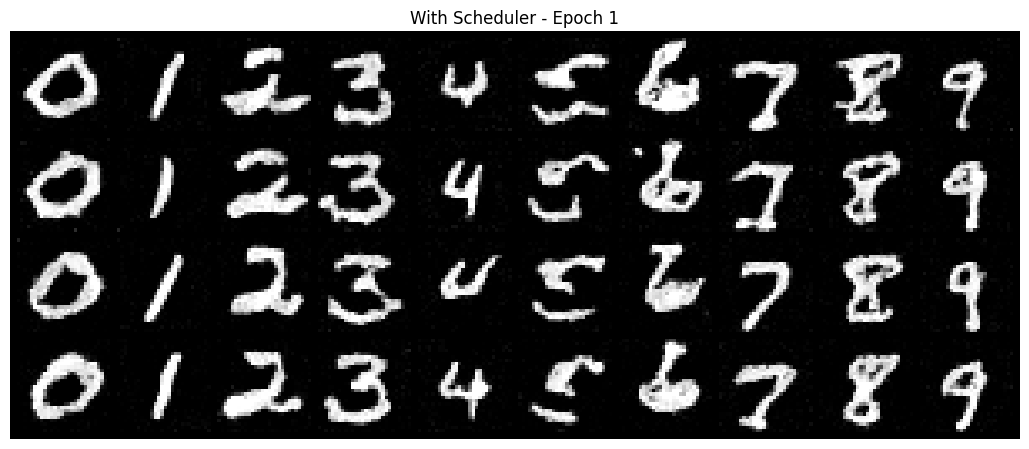

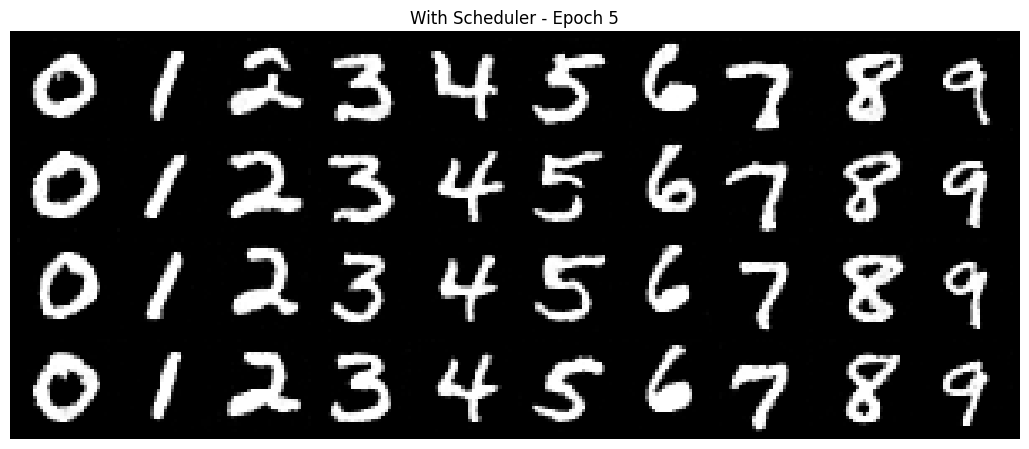

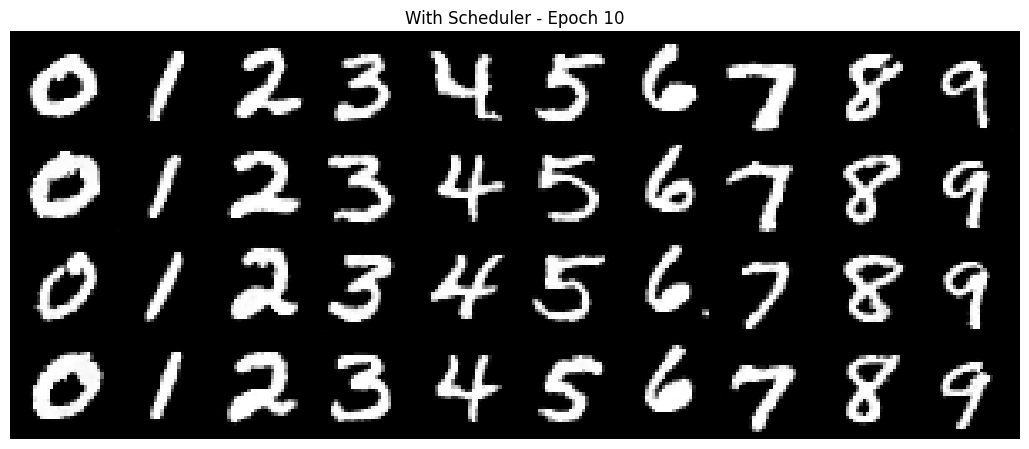

In [ ]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0.
# Keep seeds fixed for comparisons.
labels = torch.arange(10, device=device).repeat(4)

# With Scheduler
for epoch in [1, 5, 10]:
    model_path = OUT / f"class_tfm_epoch_{epoch}.pt"
    class_model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    class_model.eval()

    generated_images = class_model.sample(labels, (28, 28), guidance_scale=5.0, seed=0)

    show_grid(generated_images, f"With Scheduler - Epoch {epoch}", f"class_epoch_{epoch}.png", nrow=10)

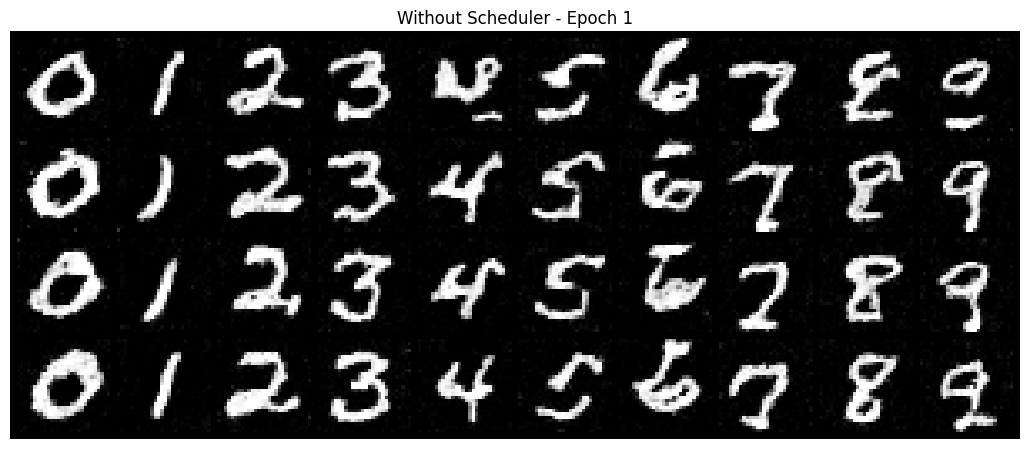

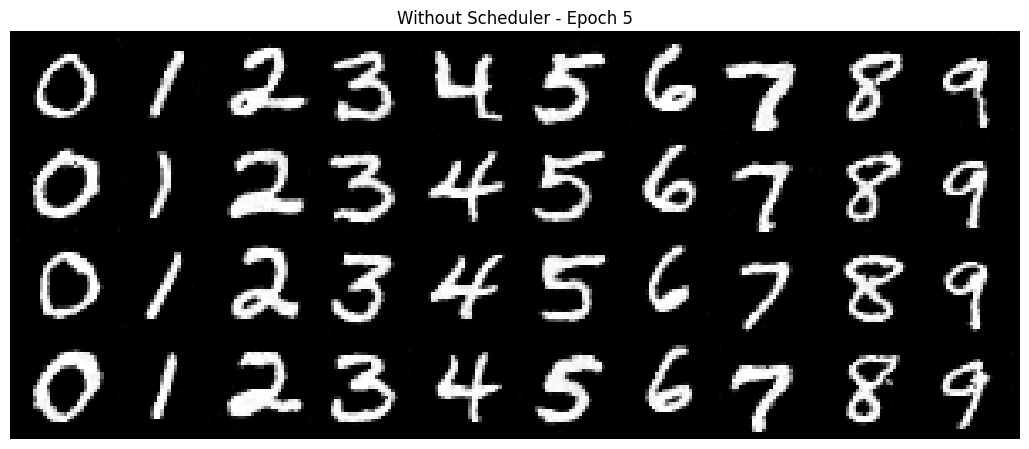

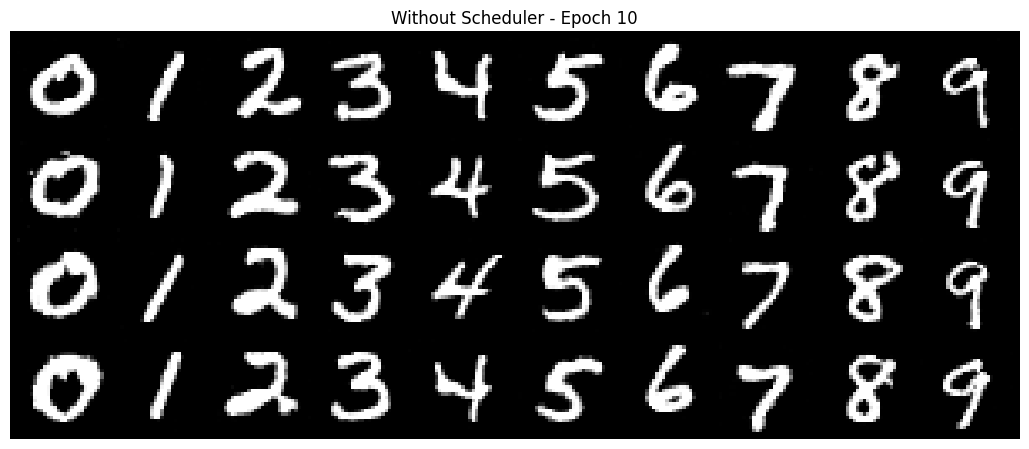

In [ ]:

# Also visualize the no-scheduler model and describe the tradeoff.
# Without Scheduler
for epoch in [1, 5, 10]:
    model_path = OUT / f"ns_class_epoch_{epoch}.pt"
    no_scheduler_class_model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    no_scheduler_class_model.eval()

    generated_images = no_scheduler_class_model.sample(labels, (28, 28), guidance_scale=5.0, seed=0)

    show_grid(generated_images, f"Without Scheduler - Epoch {epoch}", f"no_scheduler_epoch_{epoch}.png", nrow=10)
